#### Phase 2 - YOLOv8 Counter Detection

Loads what `src/train_yolo.py` produced (`models/yolo.pt`, `results/yolo/`). Nothing is retrained here.

A COCO-pretrained YOLOv8n, fine-tuned to find the counter in each photo.

In [3]:
import sys, ast, json
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

sys.path.append(str(Path.cwd().parent / "src"))
from config import CONFIG, resolve_path
from train_yolo import iou
from figures import plot_iou_histogram

np.random.seed(CONFIG["seed"])

#### 1. Sample predictions

Green = ground truth, red = detector's highest-confidence box.

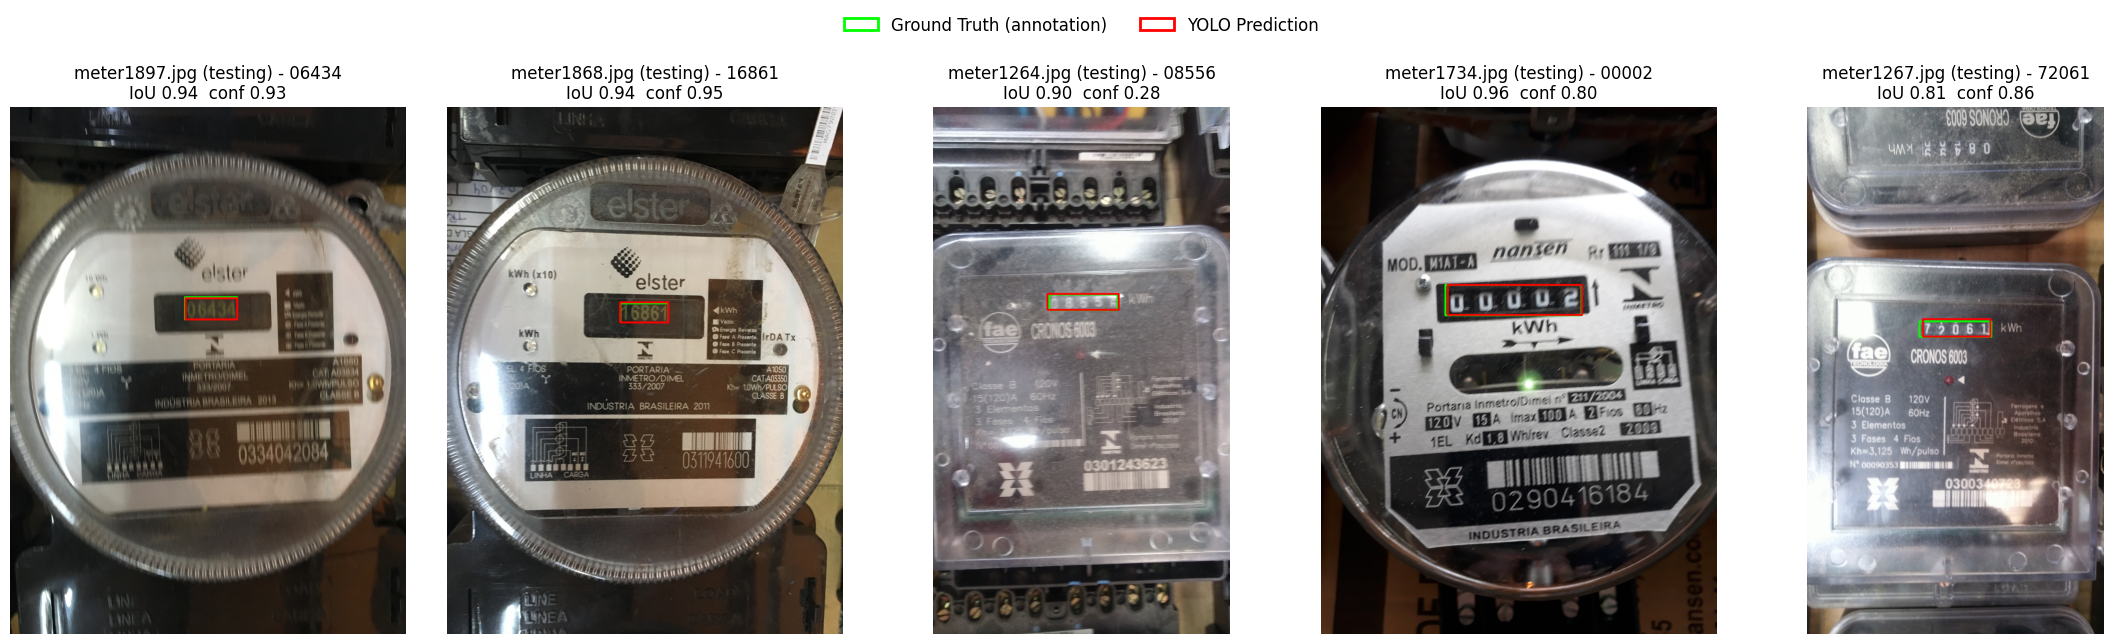

In [10]:
GT_COLOR, PRED_COLOR = (0, 255, 0), (255, 0, 0)   # RGB
from matplotlib.patches import Patch
legend_boxes = [Patch(facecolor="none", edgecolor=np.array(GT_COLOR) / 255, linewidth=2, label="Ground Truth (annotation)"),
                Patch(facecolor="none", edgecolor=np.array(PRED_COLOR) / 255, linewidth=2, label="YOLO Prediction")]


def draw_labeled_box(img, x1, y1, x2, y2, color, label, thickness=6, font_scale=0.7, font_thickness=2):
    font = cv2.FONT_HERSHEY_SIMPLEX
    cv2.rectangle(img, (x1, y1), (x2, y2), color, thickness)
    (tw, th), base = cv2.getTextSize(label, font, font_scale, font_thickness)
    ly = max(0, y1 - th - base - 8)
    cv2.rectangle(img, (x1, ly), (x1 + tw + 8, ly + th + base + 8), color, -1)
    cv2.putText(img, label, (x1 + 4, ly + th + 3), font, font_scale, (255, 255, 255), font_thickness)


df = pd.read_csv(resolve_path(CONFIG["paths"]["dataset_details"]), dtype={"reading": str})
df["counter_bbox"] = df["counter_bbox"].apply(ast.literal_eval)
test_df = df[df["split"] == "testing"]

model = YOLO(resolve_path(CONFIG["paths"]["yolo_weights"]))
sample = test_df.sample(5, random_state=CONFIG["seed"]).reset_index(drop=True)

fig, axes = plt.subplots(1, 5, figsize=(22, 6))
for ax, (_, row) in zip(axes.flat, sample.iterrows()):
    img_path = resolve_path(row["image_path"])
    result = model.predict(str(img_path), verbose=False)[0]
    img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    gx, gy, gw, gh = row["counter_bbox"]
    cv2.rectangle(img, (gx, gy), (gx + gw, gy + gh), GT_COLOR, 14)

    this_iou, label = 0.0, "no box"
    if len(result.boxes):
        best = result.boxes[result.boxes.conf.argmax()]
        x1, y1, x2, y2 = (int(v) for v in best.xyxy[0].tolist())
        this_iou = iou(row["counter_bbox"], (x1, y1, x2 - x1, y2 - y1))
        cv2.rectangle(img, (x1, y1), (x2, y2), PRED_COLOR, 14)
        label = f"IoU {this_iou:.2f}  conf {float(best.conf[0]):.2f}"
    ax.imshow(img); ax.set_title(f"{row['filename']} ({row['split']}) - {row['reading'].zfill(5)}\n{label}", fontsize=12); ax.axis("off")

plt.tight_layout()
fig.legend(handles=legend_boxes, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, fontsize=12, frameon=False)
plt.show()

#### 2. Test-set metrics

A box is correct if its IoU with the annotation is ≥ 0.5.
- **Precision**: share of drawn boxes that are correct.
- **Recall**: share of counters found.
- **mAP@0.5**: precision and recall combined over all confidence cutoffs.
- **mAP@0.5:0.95**: the same, averaged over stricter IoU levels (0.5–0.95).

In [5]:
metrics_path = resolve_path(CONFIG["paths"]["yolo_metrics"])
with open(metrics_path) as f:
    metrics = json.load(f)

print(json.dumps(metrics, indent=2))

{
  "mAP50": 0.988548063946289,
  "mAP50-95": 0.7244390947995254,
  "precision": 0.9707884450290213,
  "recall": 0.98125
}


#### 3. YOLO IoU performance on the test set

IoU of the box the pipeline uses (highest confidence); a miss counts as 0.

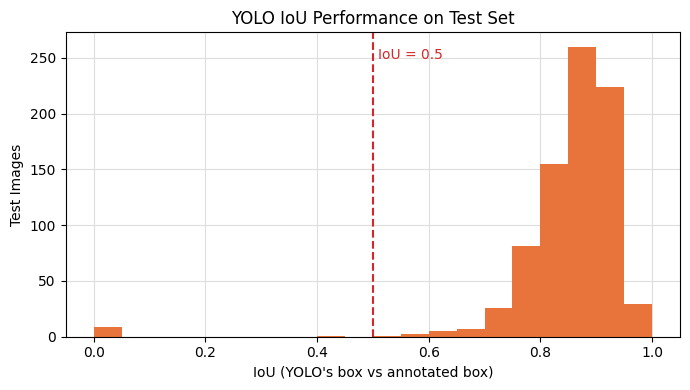

test images: 800 total - 790 OK, 7 LOW_IOU (<0.5), 3 MISS (no detection)
mean IoU: 0.8546, median IoU: 0.8747


In [6]:
preds_path = resolve_path(CONFIG["paths"]["yolo_test_predictions"])
preds_df = pd.read_csv(preds_path)

mean_iou = preds_df["iou"].mean()
median_iou = preds_df["iou"].median()
n_miss = (preds_df["status"] == "MISS").sum()
n_low = (preds_df["status"] == "LOW_IOU").sum()
n_ok = (preds_df["status"] == "OK").sum()

plot_iou_histogram()   # src/figures.py; evaluate.py saves the same figure for the Inspector
plt.show()

print(f"test images: {len(preds_df)} total - {n_ok} OK, {n_low} LOW_IOU (<0.5), {n_miss} MISS (no detection)")
print(f"mean IoU: {mean_iou:.4f}, median IoU: {median_iou:.4f}")

#### 4. Detection failures (IoU < 0.5)

Green = ground truth, red = detector box. Saved to `results/yolo/low_iou_cases.jpg`.

     filename  status  confidence      iou
meter1291.jpg LOW_IOU    0.874230 0.000000
meter1426.jpg LOW_IOU    0.316329 0.000000
meter1405.jpg LOW_IOU    0.862906 0.000000
meter1733.jpg LOW_IOU    0.771095 0.000000
meter1292.jpg LOW_IOU    0.883213 0.000000
meter1919.jpg LOW_IOU    0.909180 0.000000
meter1688.jpg LOW_IOU    0.735895 0.415125
meter1370.jpg    MISS         NaN 0.000000
meter1369.jpg    MISS         NaN 0.000000
meter1445.jpg    MISS         NaN 0.000000


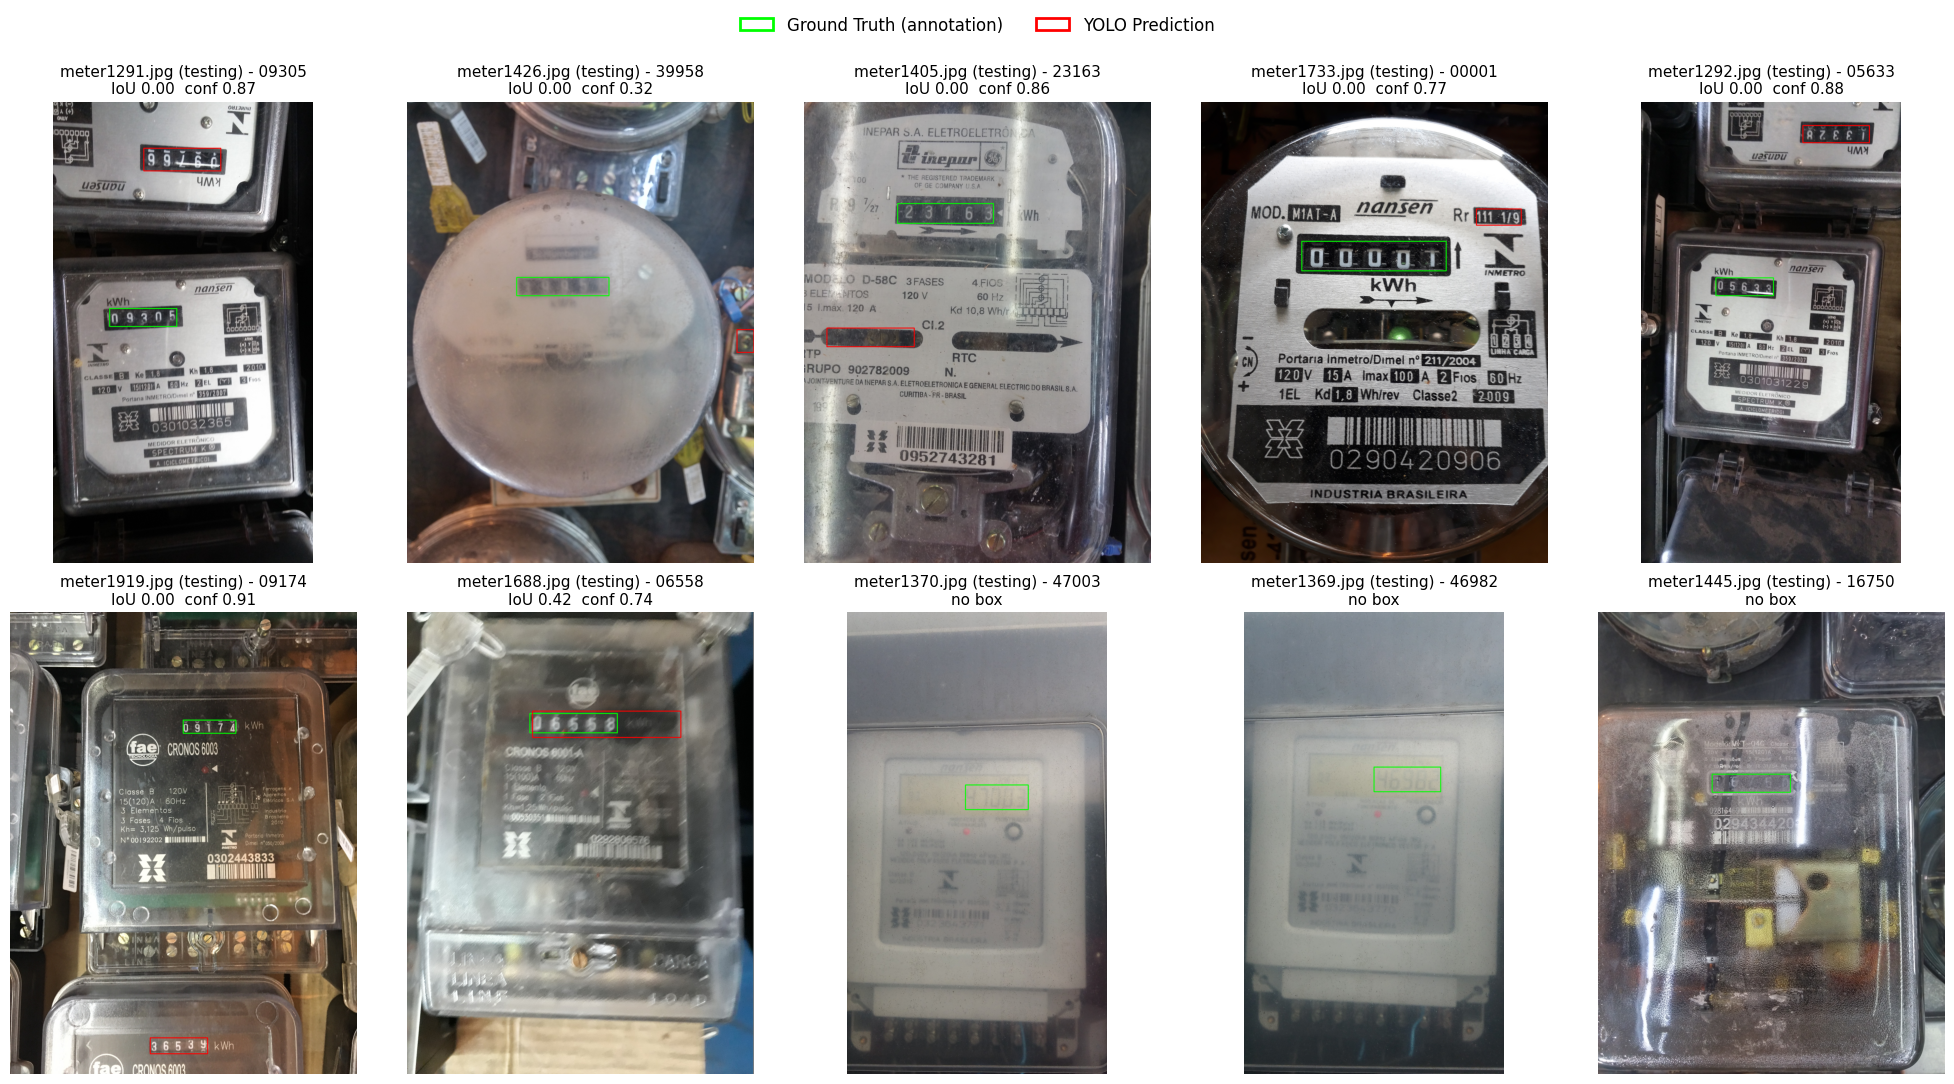

In [7]:
from predicted_crops import build_predicted_crops

index = build_predicted_crops("testing")   # the pipeline's cached boxes
details = pd.read_csv(resolve_path(CONFIG["paths"]["dataset_details"]), dtype={"reading": str})
details["counter_bbox"] = details["counter_bbox"].apply(ast.literal_eval)
gt_boxes = dict(zip(details["filename"], details["counter_bbox"]))
info = details.set_index("filename")

failures = preds_df[preds_df["iou"] < 0.5].sort_values(["status", "iou"]).reset_index(drop=True)
print(failures[["filename", "status", "confidence", "iou"]].to_string(index=False))

ncol = 5
nrow = -(-len(failures) // ncol)
fig, axes = plt.subplots(nrow, ncol, figsize=(4 * ncol, 5.2 * nrow))
for ax in axes.flat:
    ax.axis("off")
for ax, row in zip(axes.flat, failures.itertuples()):
    img = cv2.cvtColor(cv2.imread(str(resolve_path(row.image_path))), cv2.COLOR_BGR2RGB)
    gx, gy, gw, gh = gt_boxes[row.filename]
    cv2.rectangle(img, (gx, gy), (gx + gw, gy + gh), GT_COLOR, 8)
    entry = index[row.filename.rsplit(".", 1)[0]]
    if entry["detected"]:
        x, y, w, h = entry["bbox"]
        cv2.rectangle(img, (x, y), (x + w, y + h), PRED_COLOR, 8)
        label = f"IoU {row.iou:.2f}  conf {row.confidence:.2f}"
    else:
        label = "no box"
    ax.imshow(img)
    split, reading = info.loc[row.filename, ["split", "reading"]]
    ax.set_title(f"{row.filename} ({split}) - {reading.zfill(5)}\n{label}", fontsize=11)

plt.tight_layout()
fig.legend(handles=legend_boxes, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, fontsize=12, frameon=False)
fig.savefig(resolve_path(CONFIG["paths"]["yolo_test_predictions"]).parent / "low_iou_cases.jpg", dpi=100, bbox_inches="tight")
plt.show()

#### 5. Training curves

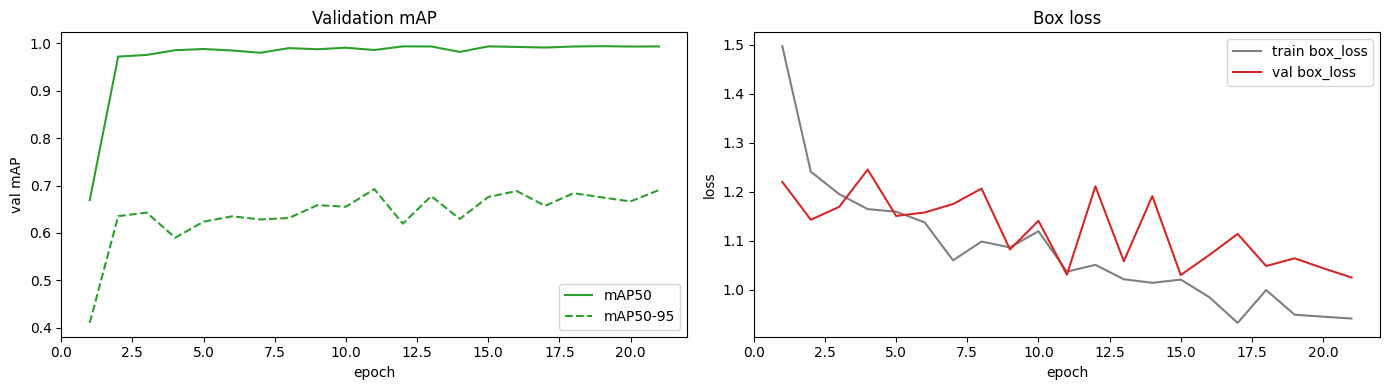

trained for 21 epochs (early stopping patience=10)


In [8]:
runs_csv = resolve_path(CONFIG["paths"]["yolo_training_history"])
if runs_csv.exists():
    hist = pd.read_csv(runs_csv)
    hist.columns = [c.strip() for c in hist.columns]

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].plot(hist["epoch"], hist["metrics/mAP50(B)"], label="mAP50", color="#2ca02c")
    axes[0].plot(hist["epoch"], hist["metrics/mAP50-95(B)"], label="mAP50-95", color="#2ca02c", linestyle="--")
    axes[0].set_xlabel("epoch"); axes[0].set_ylabel("val mAP"); axes[0].legend(); axes[0].set_title("Validation mAP")

    axes[1].plot(hist["epoch"], hist["train/box_loss"], label="train box_loss", color="#7f7f7f")
    axes[1].plot(hist["epoch"], hist["val/box_loss"], label="val box_loss", color="#d62728")
    axes[1].set_xlabel("epoch"); axes[1].set_ylabel("loss"); axes[1].legend(); axes[1].set_title("Box loss")

    plt.tight_layout()
    plt.show()
    print(f"trained for {len(hist)} epochs (early stopping patience={CONFIG['yolo']['patience']})")
else:
    print(f"{runs_csv} not found - run src/train_yolo.py first")


**Observation:** mAP@0.5 reaches 0.97 by epoch 2 (COCO pretraining) and plateaus at ~0.99. Validation loss does not rise, so no overfitting. Early stopping ended training at epoch 21; the best model (epoch 11) was kept.

#### 6. Try it on any image

Set `TEST_IMAGE_PATH` and run. All boxes above `CONF_THRESHOLD` are drawn.

counter bbox (x1,y1,x2,y2): (999, 1694, 1874, 1909)  confidence: 0.768


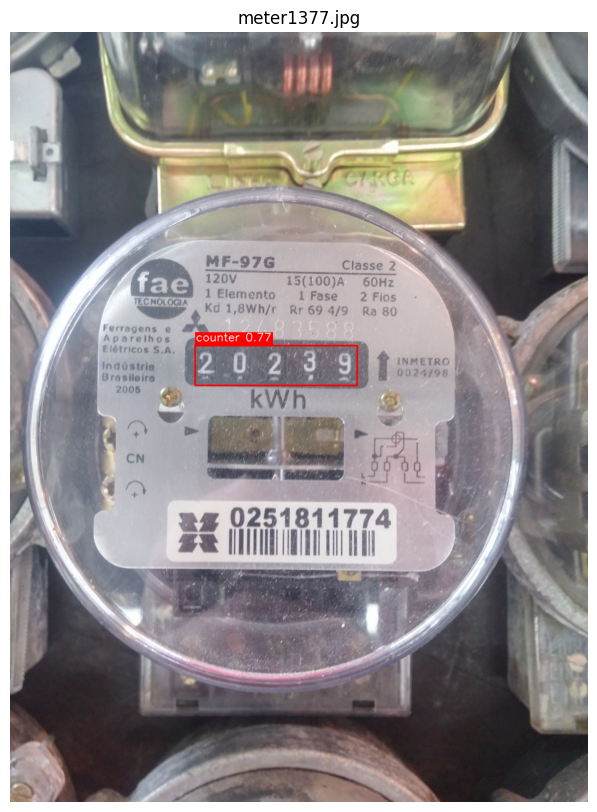

In [9]:
TEST_IMAGE_PATH = "data/raw/testing/meter1377.jpg"
CONF_THRESHOLD = 0.15

img_path = resolve_path(TEST_IMAGE_PATH)
result = model.predict(str(img_path), conf=CONF_THRESHOLD, verbose=False)[0]
img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
if not len(result.boxes):
    print("no counter detected at this confidence threshold")
for box in result.boxes:
    x1, y1, x2, y2 = (int(v) for v in box.xyxy[0].tolist())
    conf = float(box.conf[0])
    draw_labeled_box(img, x1, y1, x2, y2, PRED_COLOR, f"counter {conf:.2f}", thickness=8, font_scale=2.0, font_thickness=4)
    print(f"counter bbox (x1,y1,x2,y2): ({x1}, {y1}, {x2}, {y2})  confidence: {conf:.3f}")

plt.figure(figsize=(8, 10))
plt.imshow(img); plt.axis("off"); plt.title(img_path.name)
plt.show()